In [1]:
!pip3 install scanpy==1.9.3

In [2]:
!pip3 install scib-metrics==0.5.1 #bug in version from requirements

In [3]:
!pip3 install leidenalg==0.10.1

In [4]:
!pip3 install louvain==0.8.1

## Imports

In [5]:
import scanpy as sc
import numpy as np
import pandas as pd
import metrics_lib as metrics
import os

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2024-03-26 17:18:32.715170: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9373] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-26 17:18:32.717531: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-26 17:18:34.006990: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1534] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Set global variables

In [6]:
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Data'))
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results'))

In [7]:
#set variables to subset data
dataset="Thienpont_2018_10Xv2"
condition="TUM"
mode="sample"

## load and prep Data

### load and prep embedding 

In [8]:
adata = sc.read_h5ad(f"{DATA_DIR}/Mapping/combined_embedding_klweight_1_pleimorphic_carc_removed.h5ad")

In [9]:
#add binary condition column
adata.obs["condition"]="NML"
adata.obs.loc[adata.obs.lung_condition=="Tumor","condition"]="TUM"

In [10]:
#make dataset one for thienpont
adata.obs.dataset = adata.obs.dataset.astype(str)
adata.obs.loc[adata.obs.core_or_extension=="extension","dataset"]=dataset
adata.obs.dataset = adata.obs.dataset.astype("category")

In [11]:
# make X to obsm
adata.obsm["X_scanvi"] = adata.X

In [12]:
#subset to dataset
adata=adata[(adata.obs.dataset == dataset )|(adata.obs['core_or_extension']=="core") ].copy()

In [13]:
#subset to condition
adata=adata[(adata.obs.condition == condition )|(adata.obs['core_or_extension']=="core") ].copy()

In [14]:
adata

AnnData object with n_obs × n_vars = 643665 × 30
    obs: "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'assay_ontology_term_id', 'cause_of_death', 'cell_from_tumor', 'cell_type_ontology_term_id', 'core_or_extension', 'dataset', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'donor_id', 'fresh_or_frozen', 'is_primary_data', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'n_genes_detected', 'organism_ontology_term_id', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'self_reported_ethnicity_ontology_term_id', 'sequencing_platform', 'sex_ontology_term_id', 'smoking_status', 'study', 'subject_ID', 'subject_type', 'suspension_type', 'tissue_


### load and prep query_counts

In [15]:
adata_query=sc.read_h5ad(f"{DATA_DIR}/Query_counts/subsetted_HLCA.h5ad")

In [16]:
adata_query

AnnData object with n_obs × n_vars = 209101 × 56295
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', '

In [17]:
del adata_query.obsm["X_scanvi_emb"] #not the one we are working with

In [18]:
adata_query.obs.dataset.cat.categories

Index(['Eils_2020', 'Sheppard_2020', 'Thienpont_2018_10Xv2'], dtype='object')

In [19]:
#set obs

In [20]:
adata[adata.obs.core_or_extension=="extension"].obs.index

Index(['BT1238_AAATCAACTGCCTC', 'BT1238_AACATTGACCTAAG',
       'BT1238_AACCAGTGCTTAGG', 'BT1238_AACCTACTCGCTAA',
       'BT1238_AACTCTTGCTGTAG', 'BT1238_AACTTGCTACTCTT',
       'BT1238_AAGCCTGATTCCAT', 'BT1238_AAGTATACCATACG',
       'BT1238_AAGTCTCTACACGT', 'BT1238_AATCAAACGTATGC',
       ...
       'scrBT1427_TTTGGTTGTGCGCTTG', 'scrBT1427_TTTGGTTTCCAGATCA',
       'scrBT1427_TTTGTCAAGGTCATCT', 'scrBT1427_TTTGTCACAACGCACC',
       'scrBT1427_TTTGTCACAGTTCCCT', 'scrBT1427_TTTGTCACATGGTCAT',
       'scrBT1427_TTTGTCAGTACAGACG', 'scrBT1427_TTTGTCAGTCCCTTGT',
       'scrBT1427_TTTGTCATCATAGCAC', 'scrBT1427_TTTGTCATCGCCAAAT'],
      dtype='object', length=58721)

In [21]:
#new index (remove lambrechts to synchronize data index)
adata_query.obs.index= [i.strip("_lambrechts") for i in adata_query.obs.index]

In [22]:
#subset to only query of interest (dataset and condition)
adata_query =  adata_query[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [23]:
adata_query.obs = adata.obs.loc[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [24]:
adata_query.obsm["X_scanvi"] = adata[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))].X

## run metrics

In [25]:
#set some variables for running metrics
obsm_emb_key = 'X_scanvi'
donor_key= 'donor_id'
dataset_key="dataset"
sample_key="sample"
original_emb_key=None
batch_key = "dataset"

In [26]:
scib_results = metrics.calculate_scib_metrics(adata, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False)

Time to complete scib neighbors calculation: 634.789 s
Time to complete lisi_batch: 16.057 s
Time to complete kbet_batch: 2.915 s


In [27]:
symphony_results = metrics.calculate_symphony_metrics(adata, adata_query, obsm_emb_key, donor_key, dataset_key, sample_key, dry_run=False)

Time to complete symphony metrics neighbors calculation: 7.667 s
Time to complete lisi_query_donor: 1.388 s
Time to complete wiq_knn_corr: 338.176 s


In [28]:
other_results = metrics.calculate_other_metrics(adata, adata_query, obsm_emb_key, dataset_key, sample_key, dry_run=False)

/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell


Time to complete cluster_preservation_score: 186.864 s


In [29]:
#save results
adata.obs["lisi_batch"] = scib_results["lisi_batch"]["per_cell"]
adata.obs["kbet_batch"] = scib_results["kbet_batch"]["per_cell"]
adata.obs['lisi_query_donor'] = symphony_results['lisi_query_donor']["per_cell"]
adata.obs['wiq_knn_corr'] = symphony_results['wiq_knn_corr']["per_cell"]
adata.obs['cluster_preservation_score']=other_results['cluster_preservation_score']["per_cell"]

In [30]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].dropna()

,lisi_batch,kbet_batch,lisi_query_donor,wiq_knn_corr,cluster_preservation_score
BT1290_AAACCTGAGTAACCCT,1.903146e-02,0.0,2.666934e-12,-0.014248,0.0
BT1290_AAACCTGCAACGATGG,1.606711e-01,0.0,5.333868e-12,0.032456,0.0
BT1290_AAACCTGCATTAGCCA,2.468801e-02,0.0,0.000000e+00,-0.025680,0.0
BT1290_AAACCTGGTCCATGAT,8.830845e-03,0.0,0.000000e+00,-0.020752,0.0
BT1290_AAACCTGGTCCGAGTC,9.157145e-02,0.0,5.333868e-12,0.094669,0.0
...,...,...,...,...,...
BT1377_TTTATGCGTAGCGCAA,1.133892e-01,0.0,1.066774e-11,0.011216,0.0
BT1377_TTTATGCTCGGAAACG,1.648636e-01,0.0,0.000000e+00,0.038977,0.0
BT1377_TTTGCGCCAGCTCGAC,1.802622e-02,0.0,0.000000e+00,-0.068808,0.0
BT1377_TTTGGTTGTCTGCCAG,8.514949e-09,0.0,0.000000e+00,-0.018427,0.0


In [31]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].to_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv')

## Visualize 

Run Load and prep embeddings and set global variables first

In [32]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']] = pd.read_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv',index_col = "Unnamed: 0")

In [33]:
sc.pp.neighbors(adata,n_neighbors=50)

In [34]:
sc.tl.umap(adata)

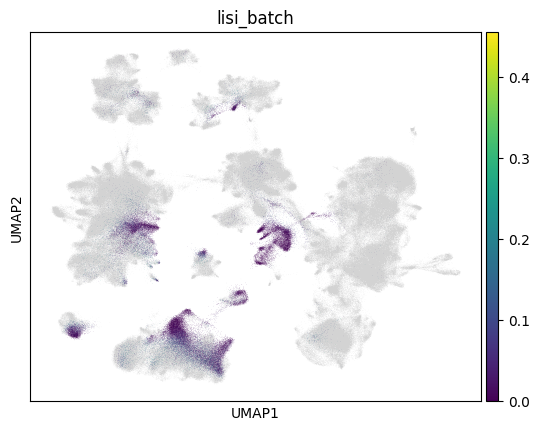

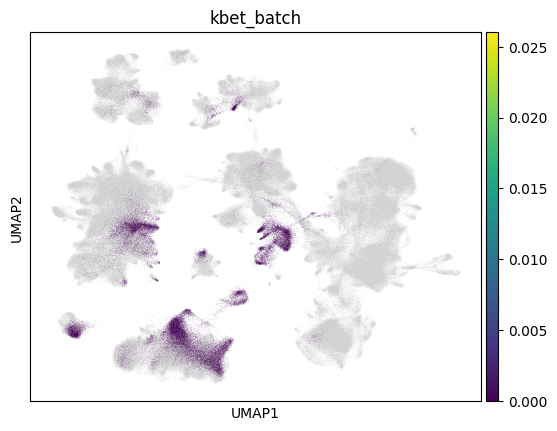

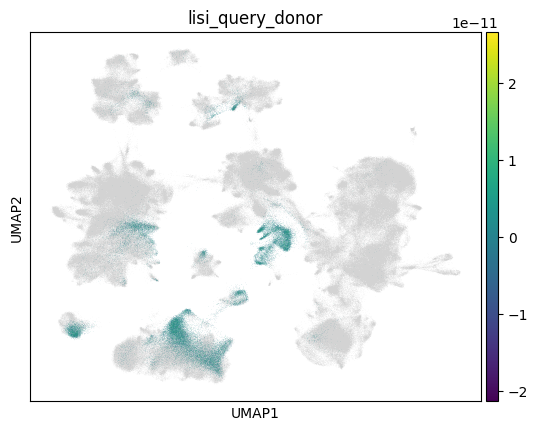

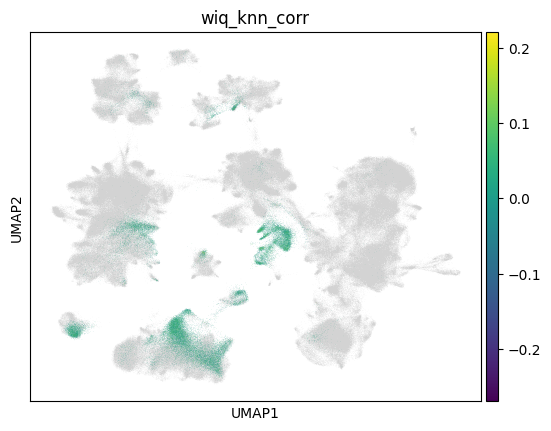

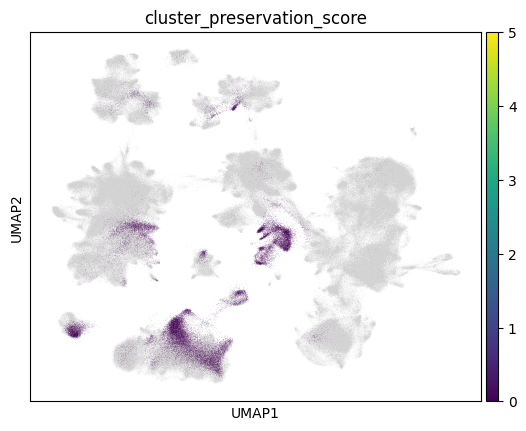

In [35]:
for metric in ["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']:
    adata.obs.loc[adata.obs.core_or_extension=="core",metric]=np.nan
    sc.pl.umap(adata,color=metric)